# Task 2 — Gestalt principles of grouping
**CLO1.** Data: `stimuli_gestalt.csv` (six panels, 284 items) and `tips.csv`.

The arrangement changes between panels, not the numbers, so every grouping a reader sees comes from layout.
Real-reader answers go in the cells marked ✏️ — they are left empty on purpose, because invented answers score zero.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# find the data folder whether the notebook sits in assignments/ or one level up
DATA = next(p for p in (Path("data"), Path("assignments/data"), Path("week2/assignments/data")) if p.exists())

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 11,
})
GREY, RED, BLUE = "#bbbbbb", "#ee6677", "#4477aa"

g = pd.read_csv(DATA / "stimuli_gestalt.csv")
tips = pd.read_csv(DATA / "tips.csv")
print(g.groupby("panel").agg(items=("x", "size"), groups=("group", "nunique")))

            items  groups
panel                    
closure        44       2
connection     48      24
continuity     48       2
enclosure      48       4
proximity      48       4
similarity     48       4


## Step 1 — All six panels in one 2×3 figure
* `enclosure`: the four rectangles are drawn by me with `matplotlib.patches.Rectangle` (no fill, grey edge) around each clump's bounding box.
* `connection`: a line joins the two items that share a `connector` value.
* `closure` has **44** items on purpose — the gap is the stimulus — so I leave it alone.
* `similarity` keeps colours spatially mixed; separating them would test proximity instead.

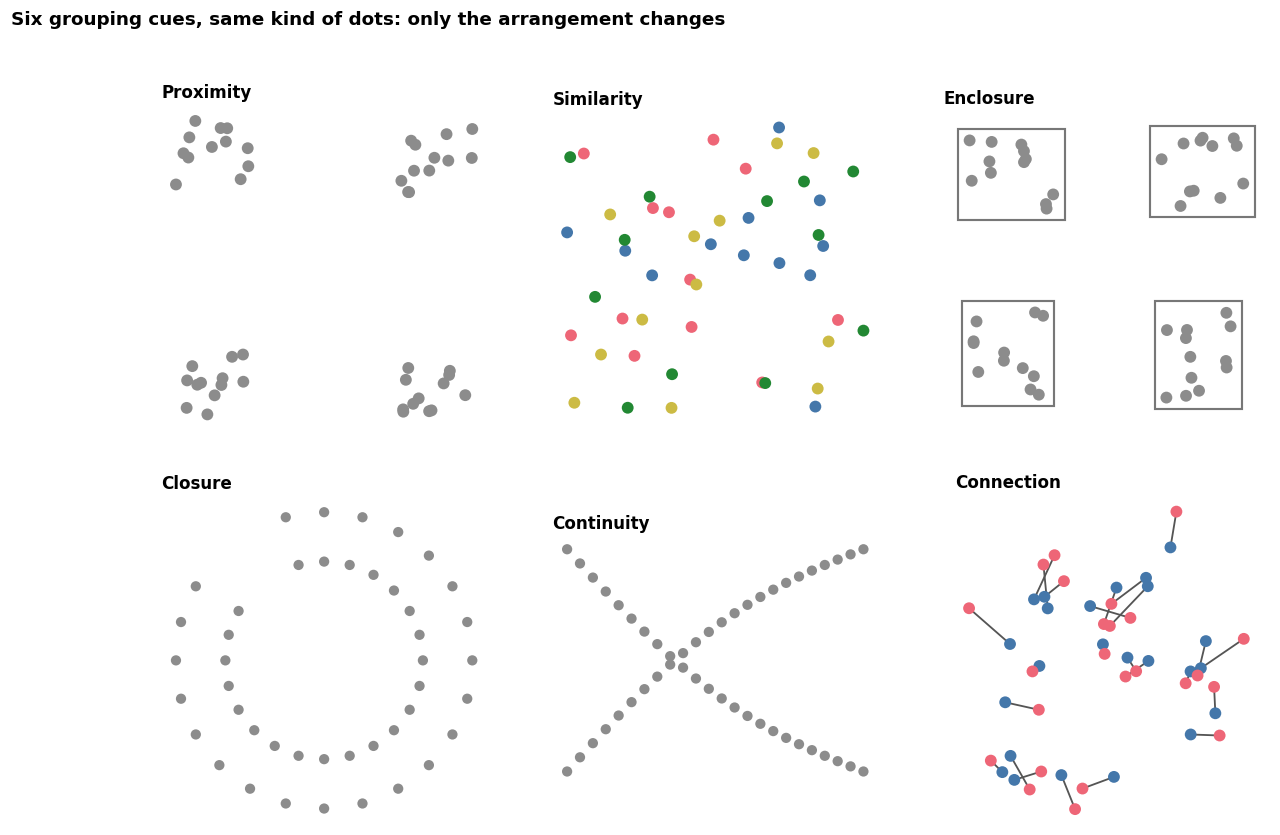

In [2]:
from matplotlib.patches import Rectangle

ORDER = ["proximity", "similarity", "enclosure", "closure", "continuity", "connection"]

def draw_panel(ax, panel, boxes=True, lines=True):
    d = g[g.panel == panel]
    fill = d.colour.map(lambda c: "#8c8c8c" if c == "grey" else c)
    ax.scatter(d.x, d.y, s=d["size"], c=fill, edgecolors="none", zorder=3)
    if panel == "enclosure" and boxes:
        for _, grp in d.groupby("group"):
            pad = 0.3
            x0, y0 = grp.x.min() - pad, grp.y.min() - pad
            ax.add_patch(Rectangle((x0, y0), grp.x.max() - grp.x.min() + 2 * pad, grp.y.max() - grp.y.min() + 2 * pad,
                                   fill=False, edgecolor="#777777", lw=1.4, zorder=2))
    if panel == "connection" and lines:
        for _, pair in d.groupby("connector"):
            ax.plot(pair.x, pair.y, color="#555555", lw=1.2, zorder=2)
    ax.set_aspect("equal"); ax.axis("off")

fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))
for ax, p in zip(axes.flat, ORDER):
    draw_panel(ax, p)
    ax.set_title(p.capitalize(), loc="left")
fig.suptitle("Six grouping cues, same kind of dots: only the arrangement changes", x=0.02, ha="left", fontweight="bold")
fig.savefig("task2_six_panels.png", dpi=200, bbox_inches="tight")
plt.show()

## Step 2 — Ask a real person, panel by panel
Show each panel (without the title!) and ask *"how many groups do you see?"*. Fill the dict below with their answers and re-run.
`None` means "not asked yet".

In [3]:
perceived = {"proximity": None, "similarity": None, "enclosure": None,
             "closure": None, "continuity": None, "connection": None}   # ✏️ fill with your reader's answers
READER = "a classmate"                                                    # ✏️ first name or "a classmate"

true_groups = g.groupby("panel").group.nunique()
table = pd.DataFrame({"principle": ORDER,
                      "true_groups": [int(true_groups[p]) for p in ORDER],
                      "perceived_groups": [perceived[p] for p in ORDER]})
table["match"] = [("yes" if pg == tg else "no") if pg is not None else "—"
                  for pg, tg in zip(table.perceived_groups, table.true_groups)]
print("Reader:", READER)
table

Reader: a classmate


,principle,true_groups,perceived_groups,match
0,proximity,4,None,—
1,similarity,4,None,—
2,enclosure,4,None,—
3,closure,2,None,—
4,continuity,2,None,—
5,connection,24,None,—


## Step 3 — Make the principles fight: connection vs similarity vs proximity
In `connection`, each pair has **two different colours** (similarity says "reds together, blues together") and the partners are
**not the nearest items** (proximity says "group by closeness"). Only the line says "these two belong together".
First, measure how strongly the geometry opposes the lines, from the data, no human needed:

In [4]:
c = g[g.panel == "connection"].reset_index(drop=True)
from scipy.spatial.distance import cdist
D = cdist(c[["x", "y"]], c[["x", "y"]]); np.fill_diagonal(D, np.inf)
nearest = D.argmin(axis=1)
partner_is_nearest = (c.connector.values == c.connector.values[nearest]).mean()
partner_same_colour = c.groupby("connector").colour.nunique().eq(1).mean()
print(f"Items whose nearest neighbour is their partner: {partner_is_nearest:.0%}")
print(f"Pairs whose two members share a colour:        {partner_same_colour:.0%}")

Items whose nearest neighbour is their partner: 31%
Pairs whose two members share a colour:        0%


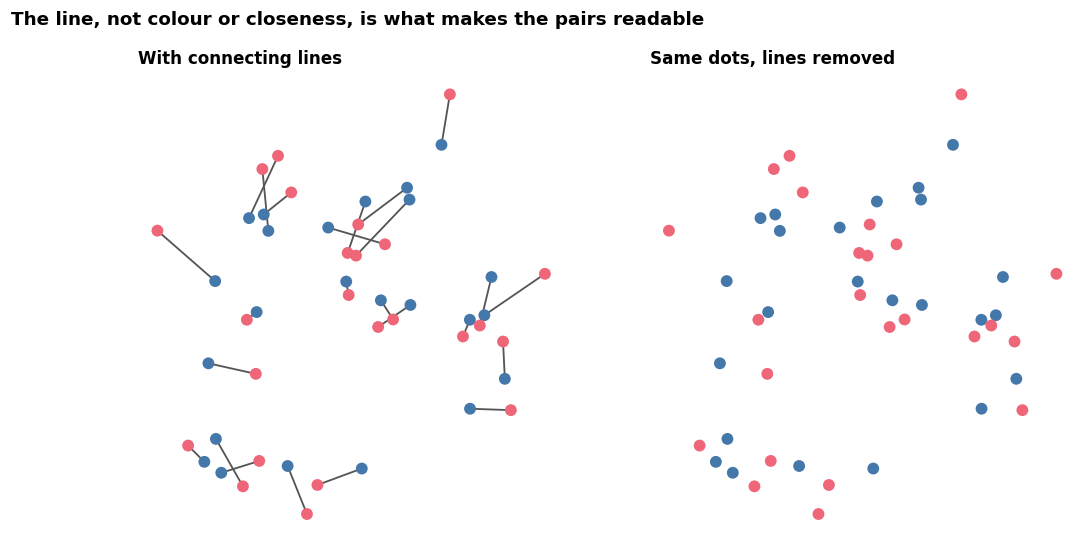

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
draw_panel(axes[0], "connection", lines=True);  axes[0].set_title("With connecting lines", loc="left")
draw_panel(axes[1], "connection", lines=False); axes[1].set_title("Same dots, lines removed", loc="left")
fig.suptitle("The line, not colour or closeness, is what makes the pairs readable", x=0.02, ha="left", fontweight="bold")
fig.savefig("task2_connection_with_without.png", dpi=200, bbox_inches="tight")
plt.show()

In [6]:
connection_reader = {"with_lines": "", "without_lines": ""}   # ✏️ what your reader said, in their words
connection_reader

{'with_lines': '', 'without_lines': ''}

> ✏️ **Which principle won?** Write what your reader actually said for each version. The expectation is that with lines they
> see pairs (connection beats similarity and proximity), and without lines they fall back on colour (two colour groups) or
> clumps. If your reader did something else, report that and give a reason — do not edit it to match the theory.

## Step 4 — Proximity in a real chart (`tips.csv`)
Mean tip percentage by day and sex. Version A makes the gap **within** a day small and the gap **between** days large, so the
days read as units. Version B spaces all eight bars equally; the data are identical.

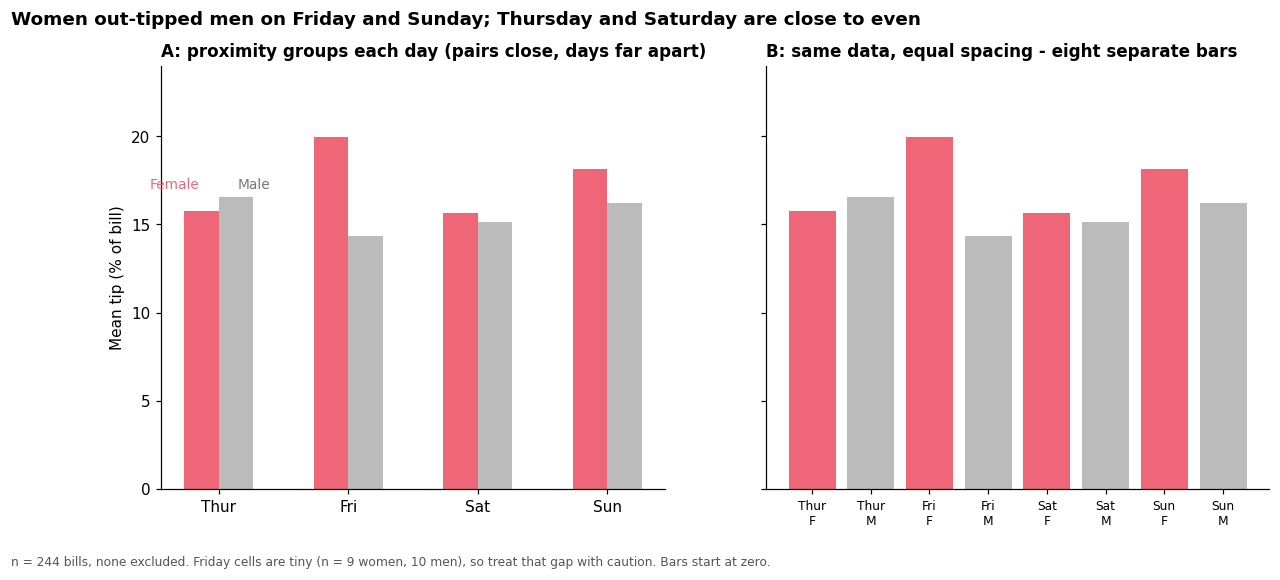

sex,Female_mean_pct,Male_mean_pct,Female_n,Male_n
day,,,,
Thur,15.8,16.5,32,30
Fri,19.9,14.3,9,10
Sat,15.6,15.2,28,59
Sun,18.2,16.2,18,58


In [7]:
tips["tip_pct"] = tips.tip / tips.total_bill * 100
days = ["Thur", "Fri", "Sat", "Sun"]
m = tips.groupby(["day", "sex"]).tip_pct.mean().unstack().loc[days]
n = tips.groupby(["day", "sex"]).size().unstack().loc[days]
W = 0.8

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

# Version A: proximity - tight pairs, wide gaps between days
ax = axes[0]
centres = np.arange(4) * 3.0
ax.bar(centres - W / 2, m["Female"], W, color=RED, label="Female")
ax.bar(centres + W / 2, m["Male"], W, color=GREY, label="Male")
ax.set_xticks(centres); ax.set_xticklabels(days)
top = max(m.loc["Thur", "Female"], m.loc["Thur", "Male"]) + 0.5
ax.text(centres[0] - W / 2 - 0.05, top, "Female", ha="right", color=RED, fontsize=9)
ax.text(centres[0] + W / 2 + 0.05, top, "Male", ha="left", color="#777777", fontsize=9)
ax.set_title("A: proximity groups each day (pairs close, days far apart)", loc="left")
ax.set_ylabel("Mean tip (% of bill)")

# Version B: equal gaps - proximity no longer groups anything
ax = axes[1]
pos = np.arange(8) * 1.0
vals = [v for d in days for v in (m.loc[d, "Female"], m.loc[d, "Male"])]
cols = [c for _ in days for c in (RED, GREY)]
ax.bar(pos, vals, 0.8, color=cols)
ax.set_xticks(pos); ax.set_xticklabels([f"{d}\n{s}" for d in days for s in ("F", "M")], fontsize=8)
ax.set_title("B: same data, equal spacing - eight separate bars", loc="left")

for a in axes:
    a.set_ylim(0, 24)
fig.suptitle("Women out-tipped men on Friday and Sunday; Thursday and Saturday are close to even", x=0.02, ha="left", fontweight="bold")
fig.text(0.02, -0.03, f"n = {len(tips)} bills, none excluded. Friday cells are tiny (n = {n.loc['Fri','Female']} women, {n.loc['Fri','Male']} men), so treat that gap with caution. Bars start at zero.",
         fontsize=8, color="#555555")
fig.savefig("task2_tips_proximity.png", dpi=200, bbox_inches="tight")
plt.show()
display(m.round(1).join(n, lsuffix="_mean_pct", rsuffix="_n"))

**What the reader loses in Version B.** The data are identical, but the *days* disappear as units. In A, proximity tells the eye
"these two bars are one day", so comparing women and men within a day is one glance and the four days read as four clusters. In B
every bar is equidistant from its neighbours, so nothing is grouped by position; the reader has to read the tiny F/M labels and
reconstruct the pairs in working memory. The comparison the chart exists to show (female vs male on the same day) now costs
extra cognitive load, while the numbers have not moved. (Colour still separates female from male by similarity in both
versions, but it cannot say which day a bar belongs to.)

## Step 5 — Each principle in a chart you already know
| Principle | Where it already lives |
|---|---|
| **Proximity** | The bars of one category sitting together in a grouped bar chart; axis labels hugging their axis; direct labels placed beside a line end. |
| **Similarity** | Points sharing a colour or marker in a scatterplot, or a legend swatch matching a line's colour. |
| **Enclosure** | A shaded highlight band behind a recession period on a time series, or a box around an annotated cluster. |
| **Closure** | A dashed circle or a partial gridline frame that you "complete" mentally; open-sided axes (no box) still read as a complete chart area. |
| **Continuity** | A line chart's line: the eye follows one smooth path through the points and keeps two crossing lines separate. |
| **Connection** | The line joining before/after dots in a slope chart; table rules linking a row's cells; tree and flow diagram edges. |

## The question to answer: what does direct labelling do that a legend does not?
A legend makes the reader **look up a colour, hold it in working memory, carry it across to the data, and match it** — each
series costs a round trip, and working memory holds only about 4 ± 1 chunks. That load is extraneous: it comes from the design,
not the data. Direct labelling swaps that memory task for **proximity** (and often connection): the name sits at the end of
its own line, so the eye reads "this label belongs to that mark" automatically, in one fixation, with nothing to hold. The
mapping is read straight off the picture instead of being stored and retrieved. That is cheaper for the brain, regardless of
whether it looks nicer.